# Лабораторная работа №1. Предобработка данных
Набор данных: Occupancy Detection (`datatraining.txt`) — показания датчиков в помещении (температура, влажность, освещённость, CO2) и целевой признак `Occupancy` (1 — в помещении есть люди, 0 — нет).

## 1. Чтение файла и проверка корректности считывания

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif, RFE
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

In [2]:
data = pd.read_csv('datatraining.txt')  # первый столбец без заголовка pandas сам делает индексом
data.head()

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
1,2015-02-04 17:51:00,23.18,27.2720,426.0,721.25,0.004793,1
2,2015-02-04 17:51:59,23.15,27.2675,429.5,714.00,0.004783,1
3,2015-02-04 17:53:00,23.15,27.2450,426.0,713.50,0.004779,1
4,2015-02-04 17:54:00,23.15,27.2000,426.0,708.25,0.004772,1
5,2015-02-04 17:55:00,23.10,27.2000,426.0,704.50,0.004757,1


In [3]:
data.tail()

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
8139,2015-02-10 09:29:00,21.05,36.0975,433.0,787.250000,0.005579,1
8140,2015-02-10 09:29:59,21.05,35.9950,433.0,789.500000,0.005563,1
8141,2015-02-10 09:30:59,21.10,36.0950,433.0,798.500000,0.005596,1
8142,2015-02-10 09:32:00,21.10,36.2600,433.0,820.333333,0.005621,1
8143,2015-02-10 09:33:00,21.10,36.2000,447.0,821.000000,0.005612,1


In [4]:
data.shape  # 8143 строки (как в файле без строки заголовка), 7 столбцов

(8143, 7)

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 8143 entries, 1 to 8143
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           8143 non-null   str    
 1   Temperature    8143 non-null   float64
 2   Humidity       8143 non-null   float64
 3   Light          8143 non-null   float64
 4   CO2            8143 non-null   float64
 5   HumidityRatio  8143 non-null   float64
 6   Occupancy      8143 non-null   int64  
dtypes: float64(5), int64(1), str(1)
memory usage: 445.4 KB


In [6]:
data.describe()

,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
count,8143.000000,8143.000000,8143.000000,8143.000000,8143.000000,8143.000000
mean,20.619084,25.731507,119.519375,606.546243,0.003863,0.212330
std,1.016916,5.531211,194.755805,314.320877,0.000852,0.408982
min,19.000000,16.745000,0.000000,412.750000,0.002674,0.000000
25%,19.700000,20.200000,0.000000,439.000000,0.003078,0.000000
50%,20.390000,26.222500,0.000000,453.500000,0.003801,0.000000
75%,21.390000,30.533333,256.375000,638.833333,0.004352,0.000000
max,23.180000,39.117500,1546.333333,2028.500000,0.006476,1.000000


In [7]:
data.nunique()

date             8143
Temperature       265
Humidity         1325
Light             889
CO2              2282
HumidityRatio    3582
Occupancy           2
dtype: int64

## 2. Проверка и замена пустых значений

In [8]:
data.isna().sum()

date             0
Temperature      0
Humidity         0
Light            0
CO2              0
HumidityRatio    0
Occupancy        0
dtype: int64

In [9]:
data.isna().sum().sum() / data.size * 100  # доля пропусков, %

np.float64(0.0)

## 3. Изменение структуры набора данных, регулярные выражения

In [10]:
# регулярным выражением выделяем из строки date дату, час, минуты и секунды
parts = data['date'].str.extract(r'(?P<Дата>\d{4}-\d{2}-\d{2}) (?P<Час>\d{2}):(?P<Мин>\d{2}):(?P<Сек>\d{2})')
parts.head()

,Дата,Час,Мин,Сек
1,2015-02-04,17,51,00
2,2015-02-04,17,51,59
3,2015-02-04,17,53,00
4,2015-02-04,17,54,00
5,2015-02-04,17,55,00


In [11]:
# проверка: все ли строки соответствуют шаблону
data['date'].str.fullmatch(r'\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}').all()

np.True_

In [12]:
data['Час'] = parts['Час'].astype(int)
data.index = pd.to_datetime(data['date'])          # дату-время делаем индексом
data.drop('date', axis=1, inplace=True)              # исходный строковый столбец больше не нужен
data['День_недели'] = data.index.day_name()          # категориальный признак
data['Время_суток'] = pd.cut(data['Час'], bins=[-1, 5, 11, 17, 23],
                             labels=['ночь', 'утро', 'день', 'вечер']).astype(str)  # категориальный признак
data = data[['Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio',
             'Час', 'День_недели', 'Время_суток', 'Occupancy']]  # меняем порядок: целевой признак в конец
data.head()

,Temperature,Humidity,Light,CO2,HumidityRatio,Час,День_недели,Время_суток,Occupancy
date,,,,,,,,,
2015-02-04 17:51:00,23.18,27.2720,426.0,721.25,0.004793,17,Wednesday,день,1
2015-02-04 17:51:59,23.15,27.2675,429.5,714.00,0.004783,17,Wednesday,день,1
2015-02-04 17:53:00,23.15,27.2450,426.0,713.50,0.004779,17,Wednesday,день,1
2015-02-04 17:54:00,23.15,27.2000,426.0,708.25,0.004772,17,Wednesday,день,1
2015-02-04 17:55:00,23.10,27.2000,426.0,704.50,0.004757,17,Wednesday,день,1


## 4. Кодирование категориальных признаков

In [13]:
# Метод 1. Label Encoding: каждой категории ставится в соответствие целое число
le = LabelEncoder()
data['Время_суток_код'] = le.fit_transform(data['Время_суток'])
dict(zip(le.classes_, le.transform(le.classes_)))

{'вечер': np.int64(0),
 'день': np.int64(1),
 'ночь': np.int64(2),
 'утро': np.int64(3)}

In [14]:
# Метод 2. One-hot encoding: для каждой категории свой столбец 0/1
data = pd.get_dummies(data, columns=['День_недели'], prefix='ДН', dtype=int)
data.filter(like='ДН_').head()

,ДН_Friday,ДН_Monday,ДН_Saturday,ДН_Sunday,ДН_Thursday,ДН_Tuesday,ДН_Wednesday
date,,,,,,,
2015-02-04 17:51:00,0,0,0,0,0,0,1
2015-02-04 17:51:59,0,0,0,0,0,0,1
2015-02-04 17:53:00,0,0,0,0,0,0,1
2015-02-04 17:54:00,0,0,0,0,0,0,1
2015-02-04 17:55:00,0,0,0,0,0,0,1


## 5. Визуализация данных

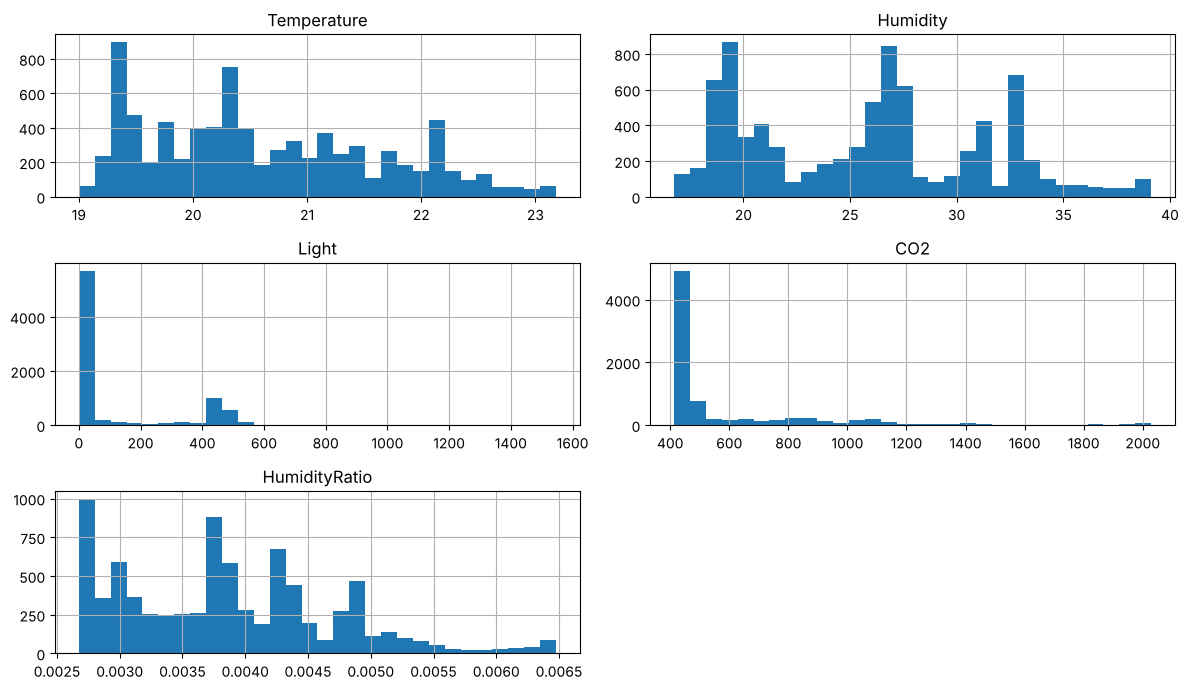

In [15]:
# 1) Гистограммы распределений числовых признаков
data[['Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio']].hist(bins=30, figsize=(12, 7))
plt.tight_layout()
plt.show()

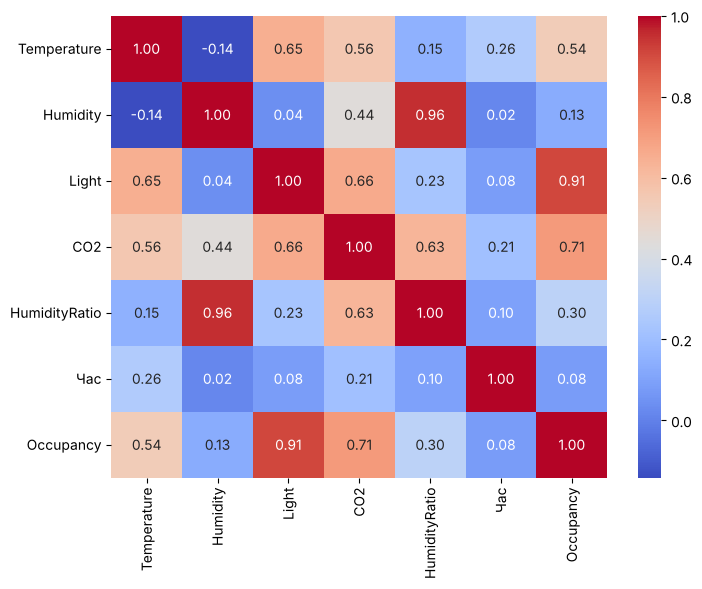

In [16]:
# 2) Матрица корреляций
plt.figure(figsize=(8, 6))
sns.heatmap(data[['Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio', 'Час', 'Occupancy']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

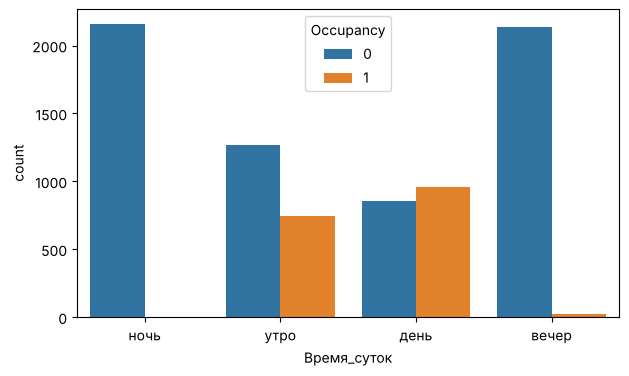

In [17]:
# 3) Столбчатая диаграмма категориального признака Время_суток в разрезе Occupancy
plt.figure(figsize=(7, 4))
sns.countplot(data=data, x='Время_суток', hue='Occupancy', order=['ночь', 'утро', 'день', 'вечер'])
plt.show()

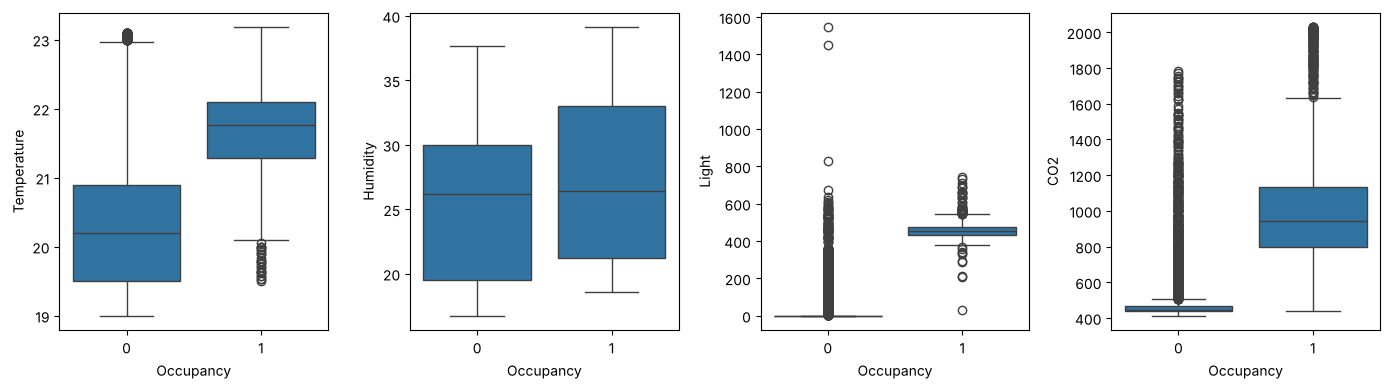

In [18]:
# 4) Диаграммы размаха (boxplot) признаков по классам Occupancy
fig, ax = plt.subplots(1, 4, figsize=(14, 4))
for a, col in zip(ax, ['Temperature', 'Humidity', 'Light', 'CO2']):
    sns.boxplot(data=data, x='Occupancy', y=col, ax=a)
plt.tight_layout()
plt.show()

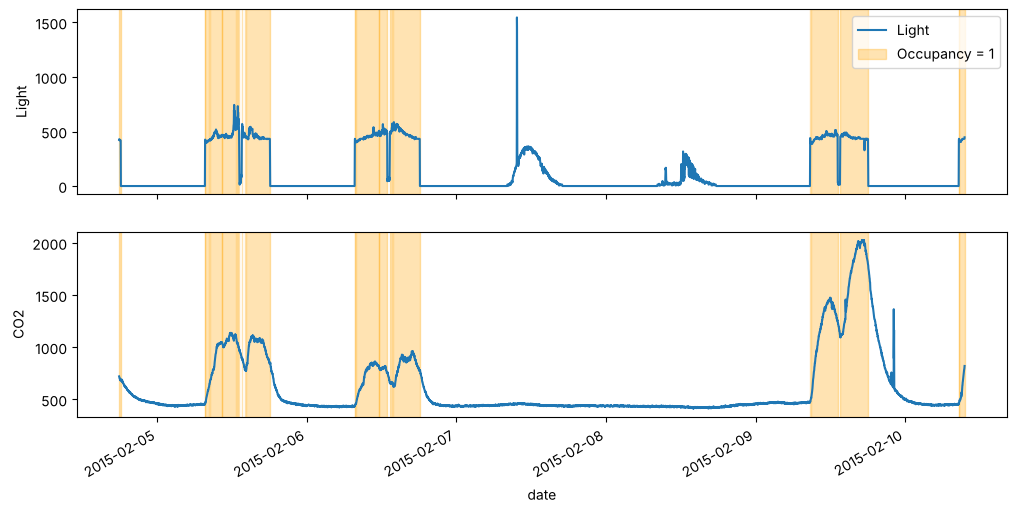

In [19]:
# 5) Линейный график (временной ряд) освещённости и CO2 с отметкой присутствия людей
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
data['Light'].plot(ax=ax[0], ylabel='Light')
data['CO2'].plot(ax=ax[1], ylabel='CO2')
for a in ax:
    a.fill_between(data.index, 0, 1, where=data['Occupancy'] == 1, color='orange', alpha=0.3,
                   transform=a.get_xaxis_transform(), label='Occupancy = 1')
ax[0].legend()
plt.show()

## 6. Добавление новых признаков и отбор признаков

In [20]:
# новый признак из существующего: выходной день (суббота, воскресенье)
data['Выходной'] = (data.index.dayofweek >= 5).astype(int)
data.groupby('Выходной')['Occupancy'].mean()

Выходной
0    0.32852
1    0.00000
Name: Occupancy, dtype: float64

In [21]:
# 6.1 Удаление признаков с низкой дисперсией (бинарные признаки; порог p(1-p), p = 0.8)
binary = [c for c in data.columns if c.startswith('ДН_')] + ['Выходной']
vt = VarianceThreshold(threshold=0.8 * (1 - 0.8)).fit(data[binary])
pd.DataFrame({'Дисперсия': vt.variances_.round(3), 'Оставить': vt.get_support()}, index=binary)

,Дисперсия,Оставить
ДН_Friday,0.146,False
ДН_Monday,0.146,False
ДН_Saturday,0.146,False
ДН_Sunday,0.146,False
ДН_Thursday,0.146,False
ДН_Tuesday,0.066,False
ДН_Wednesday,0.043,False
Выходной,0.229,True


In [22]:
data = data.drop(columns=[c for c, keep in zip(binary, vt.get_support()) if not keep])
candidates = ['Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio', 'Час', 'Время_суток_код', 'Выходной']
X_all, y_all = data[candidates], data['Occupancy']

In [23]:
# 6.2 Одномерный отбор признаков (F-критерий ANOVA), 5 лучших
skb = SelectKBest(score_func=f_classif, k=5).fit(X_all, y_all)
pd.DataFrame({'F': skb.scores_.round(1), 'Отобран': skb.get_support()}, index=candidates).sort_values('F', ascending=False)

,F,Отобран
Light,37928.3,True
CO2,8381.5,True
Temperature,3320.0,True
Выходной,1408.7,True
HumidityRatio,806.8,True
Время_суток_код,225.0,False
Humidity,146.5,False
Час,52.0,False


In [24]:
# 6.3 Рекурсивное исключение признаков (модель - дерево решений), 5 признаков
rfe = RFE(DecisionTreeClassifier(random_state=42), n_features_to_select=5).fit(X_all, y_all)
pd.DataFrame({'Ранг': rfe.ranking_, 'Отобран': rfe.support_}, index=candidates).sort_values('Ранг')

,Ранг,Отобран
Temperature,1,True
Humidity,1,True
Light,1,True
CO2,1,True
Час,1,True
Выходной,2,False
HumidityRatio,3,False
Время_суток_код,4,False


In [25]:
# итог: оставляем признаки, отобранные обоими методами
selected = [c for c, a, b in zip(candidates, skb.get_support(), rfe.support_) if a and b]
selected

['Temperature', 'Light', 'CO2']

## 7. Проверка сбалансированности классов

In [26]:
data['Occupancy'].value_counts()

Occupancy
0    6414
1    1729
Name: count, dtype: int64

In [27]:
data['Occupancy'].value_counts(normalize=True).round(3)

Occupancy
0    0.788
1    0.212
Name: proportion, dtype: float64

## 8. Разбиение на X и y, train и test

In [28]:
X = data[selected]
y = data['Occupancy']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
X_train.shape, X_test.shape, y_train.mean().round(3), y_test.mean().round(3)

((6107, 3), (2036, 3), np.float64(0.212), np.float64(0.212))

## 9. Нормализация

In [29]:
scaler = MinMaxScaler()                       # приводит каждый признак к диапазону [0; 1]
X_train_n = pd.DataFrame(scaler.fit_transform(X_train), columns=selected, index=X_train.index)  # fit только по train
X_test_n = pd.DataFrame(scaler.transform(X_test), columns=selected, index=X_test.index)
X_train_n.describe().loc[['min', 'max']]

,Temperature,Light,CO2
min,0.0,0.0,0.0
max,1.0,1.0,1.0
